# Performa Supply Chain & Delivery â€” Audit Data & EDA

**Tujuan:** memeriksa kualitas tabel-tabel Olist, membuat satu tabel analisis dengan **1 baris = 1 order**, lalu menjelajahi performa pengiriman (delivery) sebelum membuat dashboard Power BI.

**Periode data:** order e-commerce Olist tahun 2016â€“2018. Ini adalah studi kasus data historis, bukan gambaran kondisi logistik saat ini.


In [12]:
# Import library yang dibutuhkan lalu atur tampilan tabel agar lebih lebar
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)

## 1. Cari dan baca data mentah

Analisis ini memakai tabel orders, order items, customers, sellers, dan reviews. Tabel reviews bersifat opsional untuk KPI pengiriman, tetapi berguna untuk melihat pengalaman customer.

In [13]:
# Cari folder data, baca file CSV, lalu tampilkan jumlah baris dan kolom tiap tabel
REQUIRED_FILES = {
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
}
OPTIONAL_FILES = {
    "reviews": "olist_order_reviews_dataset.csv",
}

candidate_dirs = [
    Path(os.environ["OLIST_DATA_DIR"]) if os.environ.get("OLIST_DATA_DIR") else None,
    Path("data/raw"),
    Path("../data/raw"),
    Path.cwd() / "data/raw",
    Path.cwd().parent / "data/raw",
]
candidate_dirs = [p.expanduser().resolve() for p in candidate_dirs if p is not None]
DATA_DIR = next((p for p in candidate_dirs if all((p / f).exists() for f in REQUIRED_FILES.values())), None)
if DATA_DIR is None:
    searched = "\n".join(str(p) for p in candidate_dirs)
    raise FileNotFoundError(
        "File CSV Olist belum ditemukan. Taruh file inti di data/raw/ atau atur environment variable OLIST_DATA_DIR.\n"
        f"Folder yang sudah dicek:\n{searched}"
    )

print(f"Folder data: {DATA_DIR}")
data = {name: pd.read_csv(DATA_DIR / filename, low_memory=False) for name, filename in REQUIRED_FILES.items()}
for name, filename in OPTIONAL_FILES.items():
    path = DATA_DIR / filename
    data[name] = pd.read_csv(path, low_memory=False) if path.exists() else None

orders = data["orders"].copy()
items = data["items"].copy()
customers = data["customers"].copy()
sellers = data["sellers"].copy()
reviews = data["reviews"].copy() if data["reviews"] is not None else None

summary = pd.DataFrame([
    {"table": name, "rows": len(df), "columns": len(df.columns), "duplicate_rows": int(df.duplicated().sum())}
    for name, df in data.items() if df is not None
])
display(summary)

Folder data: C:\Users\ARII\Documents\proyek data analis\supply_chain_delivery_analytics_docs\supply_chain_delivery_analytics\data\raw


,table,rows,columns,duplicate_rows
0,orders,99441,8,0
1,items,112650,7,0
2,customers,99441,5,0
3,sellers,3095,4,0
4,reviews,99224,7,0


## 2. Cek struktur tabel dan kunci (key)

Aturan yang diharapkan: `orders` 1 baris per `order_id`; `items` 1 baris per `(order_id, order_item_id)`; `customers` 1 baris per `customer_id`; `sellers` 1 baris per `seller_id`.

Kalau ada pengecekan yang gagal, **selidiki dulu penyebabnya** â€” jangan langsung dihapus.

In [14]:
# Cek apakah kolom kunci (key) kosong atau duplikat, lalu lihat sebaran status order
key_checks = [
    ("orders", orders, ["order_id"]),
    ("items", items, ["order_id", "order_item_id"]),
    ("customers", customers, ["customer_id"]),
    ("sellers", sellers, ["seller_id"]),
]
key_audit = []
for table_name, frame, key_cols in key_checks:
    missing_cols = [c for c in key_cols if c not in frame.columns]
    if missing_cols:
        key_audit.append({"table": table_name, "key": ", ".join(key_cols), "missing_key_columns": missing_cols,
                          "null_key_rows": np.nan, "duplicate_key_rows": np.nan})
        continue
    null_key_mask = frame[key_cols].isna().any(axis=1)
    duplicate_key_mask = frame.duplicated(key_cols, keep=False) & ~null_key_mask
    key_audit.append({"table": table_name, "key": ", ".join(key_cols), "missing_key_columns": [],
                      "null_key_rows": int(null_key_mask.sum()), "duplicate_key_rows": int(duplicate_key_mask.sum())})
display(pd.DataFrame(key_audit))

print("Sebaran status order:")
display(orders["order_status"].value_counts(dropna=False).rename_axis("order_status").reset_index(name="orders"))

,table,key,missing_key_columns,null_key_rows,duplicate_key_rows
0,orders,order_id,[],0,0
1,items,"order_id, order_item_id",[],0,0
2,customers,customer_id,[],0,0
3,sellers,seller_id,[],0,0


Sebaran status order:


,order_status,orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


## 3. Cek data kosong (missing) dan urutan tanggal

Tanggal pengiriman yang kosong **belum tentu error**. Order yang dibatalkan (canceled), tidak tersedia (unavailable), atau belum selesai memang belum punya tanggal pengiriman. Baca data kosong bersama dengan `order_status`.

In [15]:
# Ubah kolom tanggal ke format tanggal, cek data kosong, dan cek urutan tanggal yang tidak masuk akal
timestamp_cols = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date"
]
for col in timestamp_cols:
    if col in orders.columns:
        orders[col] = pd.to_datetime(orders[col], errors="coerce")

missing_audit = pd.DataFrame({
    "missing_rows": orders.isna().sum(),
    "missing_pct": (orders.isna().mean() * 100).round(2),
}).sort_values("missing_pct", ascending=False)
display(missing_audit)

print("Rentang tanggal pembelian order:")
print(orders["order_purchase_timestamp"].min(), "sampai", orders["order_purchase_timestamp"].max())

chronology_checks = {
    "approval_before_purchase": (orders["order_approved_at"] < orders["order_purchase_timestamp"]),
    "carrier_before_purchase": (orders["order_delivered_carrier_date"] < orders["order_purchase_timestamp"]),
    "delivery_before_purchase": (orders["order_delivered_customer_date"] < orders["order_purchase_timestamp"]),
    "delivery_before_carrier_handover": (orders["order_delivered_customer_date"] < orders["order_delivered_carrier_date"]),
}
chronology_summary = pd.DataFrame([
    {"check": name, "rows_flagged": int(mask.fillna(False).sum())}
    for name, mask in chronology_checks.items()
])
display(chronology_summary)

,missing_rows,missing_pct
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_estimated_delivery_date,0,0.00


Rentang tanggal pembelian order:
2016-09-04 21:15:19 sampai 2018-10-17 17:30:18


,check,rows_flagged
0,approval_before_purchase,0
1,carrier_before_purchase,166
2,delivery_before_purchase,0
3,delivery_before_carrier_handover,23


## 4. Bangun tabel analisis dengan 1 baris = 1 order

Tabel item dirangkum (diagregasi) **sebelum** digabung ke tabel orders. Tujuannya agar jumlah order tidak menggelembung ketika satu order punya banyak item. Tabel reviews juga dirangkum per order dulu karena satu order bisa punya lebih dari satu review.

In [16]:
# Gabungkan tabel menjadi satu tabel analisis (1 baris = 1 order) dan hitung kolom turunan seperti hari pengiriman dan status terlambat
# Ubah semua kolom tanggal penting ke format tanggal secara konsisten.
for col in timestamp_cols:
    if col in items.columns:
        items[col] = pd.to_datetime(items[col], errors="coerce")

item_agg = (
    items.groupby("order_id", dropna=False)
    .agg(
        item_count=("order_item_id", "count"),
        seller_count=("seller_id", "nunique"),
        order_item_value_brl=("price", "sum"),
        total_freight_value_brl=("freight_value", "sum"),
    )
    .reset_index()
)

customer_cols = [c for c in ["customer_id", "customer_unique_id", "customer_city", "customer_state"] if c in customers.columns]
customer_dim = customers[customer_cols]  # merge(validate=...) akan error kalau key hasil audit ternyata tidak unik

fact_order_delivery = orders.merge(
    customer_dim, on="customer_id", how="left", validate="many_to_one"
).merge(
    item_agg, on="order_id", how="left", validate="one_to_one"
)

if reviews is not None and {"order_id", "review_score"}.issubset(reviews.columns):
    review_agg = (
        reviews.groupby("order_id", dropna=False)
        .agg(avg_review_score=("review_score", "mean"), review_count=("review_score", "size"))
        .reset_index()
    )
    fact_order_delivery = fact_order_delivery.merge(review_agg, on="order_id", how="left", validate="one_to_one")
else:
    fact_order_delivery["avg_review_score"] = np.nan
    fact_order_delivery["review_count"] = 0

for col in ["item_count", "seller_count", "order_item_value_brl", "total_freight_value_brl", "review_count"]:
    fact_order_delivery[col] = fact_order_delivery[col].fillna(0)

fact_order_delivery["purchase_month"] = fact_order_delivery["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
fact_order_delivery["delivery_cycle_days"] = (
    fact_order_delivery["order_delivered_customer_date"] - fact_order_delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400

actual_date = fact_order_delivery["order_delivered_customer_date"].dt.normalize()
estimated_date = fact_order_delivery["order_estimated_delivery_date"].dt.normalize()
delivered_status = fact_order_delivery["order_status"].eq("delivered")
valid_delivery_dates = delivered_status & actual_date.notna() & estimated_date.notna()
fact_order_delivery["delivery_variance_days"] = (actual_date - estimated_date).dt.days.where(valid_delivery_dates)
fact_order_delivery["late_days_if_late"] = fact_order_delivery["delivery_variance_days"].where(
    fact_order_delivery["delivery_variance_days"] > 0
)

fact_order_delivery["delivery_result"] = "not_delivered"
missing_date = delivered_status & ~valid_delivery_dates
fact_order_delivery.loc[missing_date, "delivery_result"] = "missing_delivery_date"
fact_order_delivery.loc[delivered_status & valid_delivery_dates & (actual_date <= estimated_date), "delivery_result"] = "on_time"
fact_order_delivery.loc[delivered_status & valid_delivery_dates & (actual_date > estimated_date), "delivery_result"] = "late"

fact_order_delivery["is_on_time"] = pd.Series(pd.NA, index=fact_order_delivery.index, dtype="boolean")
fact_order_delivery["is_late"] = pd.Series(pd.NA, index=fact_order_delivery.index, dtype="boolean")
fact_order_delivery.loc[valid_delivery_dates, "is_on_time"] = (actual_date[valid_delivery_dates] <= estimated_date[valid_delivery_dates]).to_numpy()
fact_order_delivery.loc[valid_delivery_dates, "is_late"] = (actual_date[valid_delivery_dates] > estimated_date[valid_delivery_dates]).to_numpy()

fact_order_delivery["purchase_to_approval_days"] = (
    fact_order_delivery["order_approved_at"] - fact_order_delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400
fact_order_delivery["purchase_to_carrier_days"] = (
    fact_order_delivery["order_delivered_carrier_date"] - fact_order_delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400
fact_order_delivery["carrier_to_customer_days"] = (
    fact_order_delivery["order_delivered_customer_date"] - fact_order_delivery["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

assert fact_order_delivery["order_id"].is_unique, "Grain salah: fact_order_delivery harus 1 baris per order_id"
assert len(fact_order_delivery) == len(orders), "Jumlah baris berubah setelah join; cek apakah ada key duplikat di tabel dimensi"

print(f"Order sumber: {len(orders):,} | Baris tabel analisis: {len(fact_order_delivery):,}")
display(fact_order_delivery.head())
display(fact_order_delivery["delivery_result"].value_counts(dropna=False).rename_axis("delivery_result").reset_index(name="orders"))

Order sumber: 99,441 | Baris tabel analisis: 99,441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,item_count,seller_count,order_item_value_brl,total_freight_value_brl,avg_review_score,review_count,purchase_month,delivery_cycle_days,delivery_variance_days,late_days_if_late,delivery_result,is_on_time,is_late,purchase_to_approval_days,purchase_to_carrier_days,carrier_to_customer_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,1.0,1.0,29.99,8.72,4.0,1.0,2017-10-01,8.436574,-8.0,NaN,on_time,True,False,0.007431,2.373924,6.062650
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,barreiras,BA,1.0,1.0,118.70,22.76,4.0,1.0,2018-07-01,13.782037,-6.0,NaN,on_time,True,False,1.279745,1.742627,12.039410
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,1.0,1.0,159.90,19.22,5.0,1.0,2018-08-01,9.394213,-18.0,NaN,on_time,True,False,0.011505,0.216100,9.178113
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,1.0,1.0,45.00,27.20,5.0,1.0,2017-11-01,13.208750,-13.0,NaN,on_time,True,False,0.012419,3.758252,9.450498
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,1.0,1.0,19.90,8.72,5.0,1.0,2018-02-01,2.873877,-10.0,NaN,on_time,True,False,0.042940,0.936053,1.937824


,delivery_result,orders
0,on_time,89936
1,late,6534
2,not_delivered,2963
3,missing_delivery_date,8


## 5. Ringkasan KPI

Definisi yang dipakai:
- **Order yang bisa dievaluasi (evaluable):** `order_status = delivered` dan tanggal pengiriman aktual serta tanggal estimasi sama-sama ada.
- **On-time (tepat waktu):** tanggal barang sampai ke customer sama dengan atau lebih awal dari tanggal estimasi.
- **Late (terlambat):** tanggal barang sampai ke customer lebih lambat dari tanggal estimasi.
- **Rata-rata keterlambatan:** rata-rata selisih hari, hanya untuk order yang terlambat.

Selalu tulis jumlah order yang dievaluasi di samping persentasenya.

In [17]:
# Hitung KPI utama: on-time rate, late rate, rata-rata hari pengiriman, dan rata-rata hari terlambat
evaluable = fact_order_delivery["delivery_result"].isin(["on_time", "late"])
late = fact_order_delivery["delivery_result"].eq("late")
on_time = fact_order_delivery["delivery_result"].eq("on_time")

kpi_summary = pd.DataFrame([{
    "all_orders": len(fact_order_delivery),
    "delivered_status_orders": int(delivered_status.sum()),
    "evaluable_delivered_orders": int(evaluable.sum()),
    "on_time_orders": int(on_time.sum()),
    "late_orders": int(late.sum()),
    "on_time_rate_pct": round(100 * on_time.sum() / evaluable.sum(), 2) if evaluable.sum() else np.nan,
    "late_rate_pct": round(100 * late.sum() / evaluable.sum(), 2) if evaluable.sum() else np.nan,
    "avg_delivery_cycle_days": round(fact_order_delivery.loc[evaluable, "delivery_cycle_days"].mean(), 2),
    "avg_delay_days_among_late_orders": round(fact_order_delivery.loc[late, "late_days_if_late"].mean(), 2),
    "delivered_but_dates_missing": int((fact_order_delivery["delivery_result"] == "missing_delivery_date").sum()),
}])
display(kpi_summary.T.rename(columns={0: "value"}))

,value
all_orders,99441.00
delivered_status_orders,96478.00
evaluable_delivered_orders,96470.00
on_time_orders,89936.00
late_orders,6534.00
on_time_rate_pct,93.23
late_rate_pct,6.77
avg_delivery_cycle_days,12.56
avg_delay_days_among_late_orders,10.62
delivered_but_dates_missing,8.00


## 6. Performa per bulan

Pada tampilan awal ini, bulan yang dipakai adalah **bulan pembelian**. Bulan paling akhir mungkin datanya belum lengkap, jadi baca dengan hati-hati.

,purchase_month,evaluable_delivered_orders,on_time_orders,late_orders,avg_delivery_cycle_days,avg_delay_days_among_late_orders,late_rate_pct,on_time_rate_pct
0,2016-09-01,1,0,1,54.81,36.00,100.0,0.0
1,2016-10-01,265,263,2,19.60,9.50,0.75,99.25
2,2016-12-01,1,1,0,4.69,NaN,0.0,100.0
3,2017-01-01,750,728,22,12.65,20.23,2.93,97.07
4,2017-02-01,1653,1604,49,13.17,20.80,2.96,97.04
5,2017-03-01,2546,2430,116,12.95,25.43,4.56,95.44
6,2017-04-01,2303,2152,151,14.92,12.34,6.56,93.44
7,2017-05-01,3545,3439,106,11.32,12.54,2.99,97.01
8,2017-06-01,3135,3040,95,12.01,14.26,3.03,96.97
9,2017-07-01,3872,3764,108,11.59,11.69,2.79,97.21


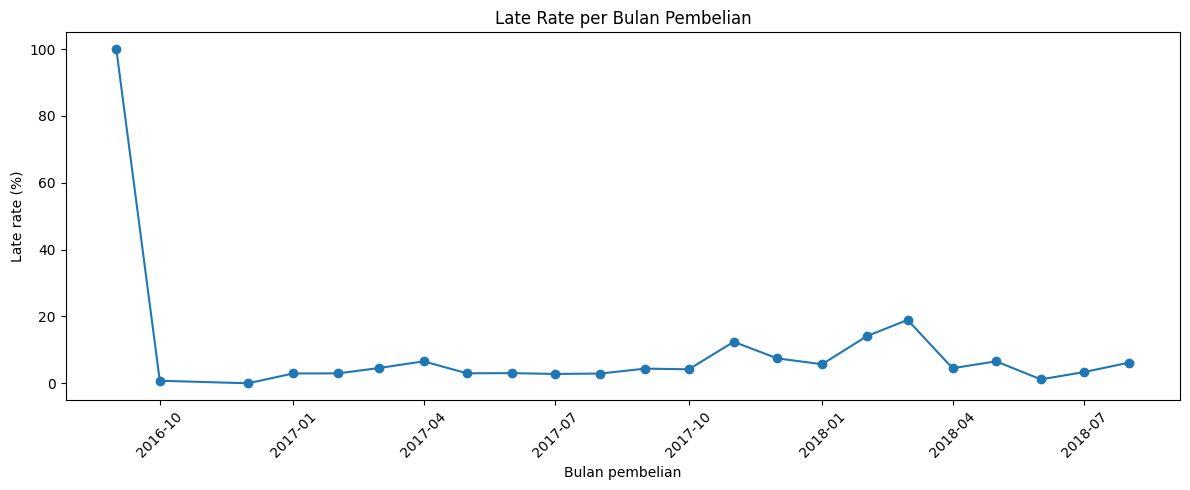

In [18]:
# Hitung performa per bulan pembelian lalu buat grafik tren late rate
monthly = (
    fact_order_delivery.loc[evaluable]
    .groupby("purchase_month")
    .agg(
        evaluable_delivered_orders=("order_id", "nunique"),
        on_time_orders=("is_on_time", "sum"),
        late_orders=("is_late", "sum"),
        avg_delivery_cycle_days=("delivery_cycle_days", "mean"),
        avg_delay_days_among_late_orders=("late_days_if_late", "mean"),
    )
    .reset_index()
)
monthly["late_rate_pct"] = 100 * monthly["late_orders"] / monthly["evaluable_delivered_orders"]
monthly["on_time_rate_pct"] = 100 * monthly["on_time_orders"] / monthly["evaluable_delivered_orders"]
display(monthly.round(2))

if not monthly.empty:
    plt.figure(figsize=(12, 5))
    plt.plot(monthly["purchase_month"], monthly["late_rate_pct"], marker="o")
    plt.title("Late Rate per Bulan Pembelian")
    plt.xlabel("Bulan pembelian")
    plt.ylabel("Late rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 7. Eksplorasi wilayah (geografi)

Perbandingan antar state bisa menyesatkan kalau jumlah ordernya sedikit. Tabel ini memakai batas minimal **100 order yang dievaluasi** sebagai ambang awal. Boleh diubah kalau ada alasannya, tetapi tulis ambangnya di laporan akhir.

,customer_state,evaluable_delivered_orders,late_orders,avg_delivery_cycle_days,late_rate_pct
1,AL,397,85,24.54,21.41
9,MA,717,125,21.57,17.43
24,SE,335,51,21.52,15.22
16,PI,476,66,19.46,13.87
5,CE,1279,176,21.27,13.76
4,BA,3256,396,19.34,12.16
18,RJ,12350,1495,15.31,12.11
13,PA,946,106,23.77,11.21
7,ES,1995,214,15.79,10.73
14,PB,517,54,20.43,10.44


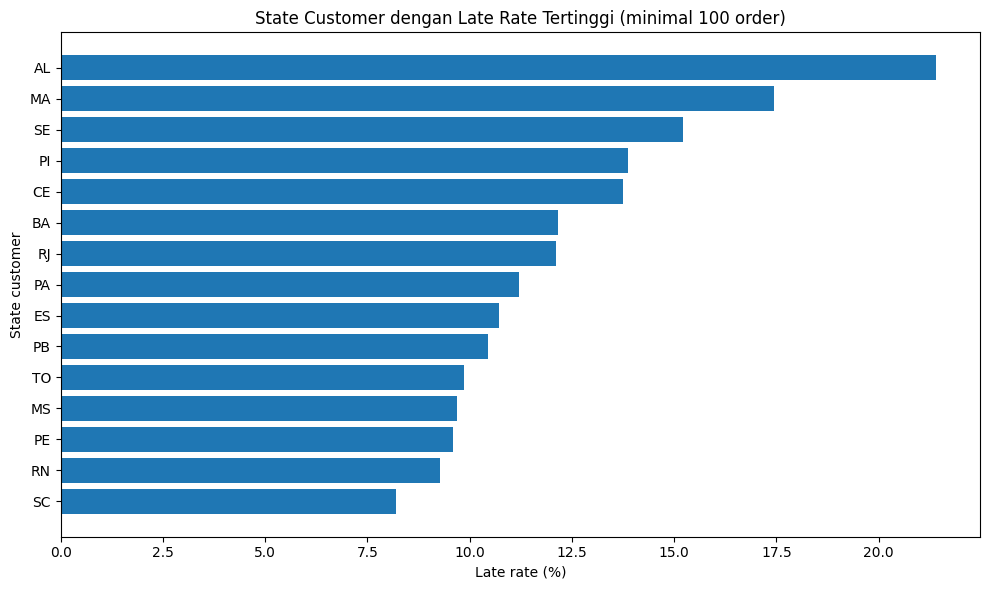

In [19]:
# Hitung performa per state customer (minimal 100 order) lalu buat grafik batang
if "customer_state" in fact_order_delivery.columns:
    geo = (
        fact_order_delivery.loc[evaluable]
        .groupby("customer_state")
        .agg(
            evaluable_delivered_orders=("order_id", "nunique"),
            late_orders=("is_late", "sum"),
            avg_delivery_cycle_days=("delivery_cycle_days", "mean"),
        )
        .reset_index()
    )
    geo["late_rate_pct"] = 100 * geo["late_orders"] / geo["evaluable_delivered_orders"]
    geo = geo.loc[geo["evaluable_delivered_orders"] >= 100].sort_values("late_rate_pct", ascending=False)
    display(geo.round(2))

    if not geo.empty:
        plot_geo = geo.head(15).sort_values("late_rate_pct")
        plt.figure(figsize=(10, 6))
        plt.barh(plot_geo["customer_state"], plot_geo["late_rate_pct"])
        plt.title("State Customer dengan Late Rate Tertinggi (minimal 100 order)")
        plt.xlabel("Late rate (%)")
        plt.ylabel("State customer")
        plt.tight_layout()
        plt.show()

## 8. Analisis seller dengan level data yang benar

Untuk performa per seller, hilangkan duplikat dulu sehingga menjadi 1 baris per `(order_id, seller_id)`. Kalau baris item dihitung langsung sebagai order, seller dengan banyak item dalam satu order akan terhitung berlebihan.

In [20]:
# Hitung performa per seller (1 baris per pasangan order-seller, minimal 50 order)
order_seller_pairs = items[["order_id", "seller_id"]].drop_duplicates()
seller_delivery = order_seller_pairs.merge(
    orders[["order_id", "order_status", "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]],
    on="order_id", how="left", validate="many_to_one"
)
seller_delivery = seller_delivery.merge(
    sellers[[c for c in ["seller_id", "seller_city", "seller_state"] if c in sellers.columns]],
    on="seller_id", how="left", validate="many_to_one"
)
actual_s = pd.to_datetime(seller_delivery["order_delivered_customer_date"], errors="coerce").dt.normalize()
estimated_s = pd.to_datetime(seller_delivery["order_estimated_delivery_date"], errors="coerce").dt.normalize()
seller_delivery["evaluable"] = seller_delivery["order_status"].eq("delivered") & actual_s.notna() & estimated_s.notna()
seller_delivery["is_late"] = (actual_s > estimated_s).where(seller_delivery["evaluable"])

seller_metrics = (
    seller_delivery.loc[seller_delivery["evaluable"]]
    .groupby(["seller_id", "seller_state"], dropna=False)
    .agg(evaluable_order_seller_pairs=("order_id", "nunique"), late_orders=("is_late", "sum"))
    .reset_index()
)
seller_metrics["late_rate_pct"] = 100 * seller_metrics["late_orders"] / seller_metrics["evaluable_order_seller_pairs"]
seller_metrics = seller_metrics.loc[seller_metrics["evaluable_order_seller_pairs"] >= 50].sort_values("late_rate_pct", ascending=False)
display(seller_metrics.head(20).round(2))

,seller_id,seller_state,evaluable_order_seller_pairs,late_orders,late_rate_pct
1000,54965bbe3e4f07ae045b90b0b8541f52,PR,73,22,30.136986
2211,beadbee30901a7f61d031b6b686095ad,SP,64,15,23.4375
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,SP,96,21,21.875
1336,712e6ed8aa4aa1fa65dab41fed5737e4,SC,77,16,20.779221
79,06a2c3af7b3aee5d69171b0e14f0ee87,MA,389,74,19.023136
2720,ea566164622c6b439516ab18062c42cd,SP,50,9,18.0
2,002100f778ceb8431b7a1020ff7ab48f,SP,50,9,18.0
2365,cac4c8e7b1ca6252d8f20b2fc1a2e4af,SP,74,13,17.567568
1141,6039e27294dc75811c0d8a39069f52c0,SP,63,11,17.460317
1606,88460e8ebdecbfecb5f9601833981930,PR,246,42,17.073171


## 9. Analisis pengalaman customer (opsional)

Hanya berjalan kalau file CSV review tersedia. Baca hasilnya sebagai **hubungan (asosiasi)**: keterlambatan saja belum membuktikan bahwa itulah penyebab skor review rendah.

In [21]:
# Bandingkan rata-rata skor review antara order tepat waktu dan terlambat
if "avg_review_score" in fact_order_delivery.columns and fact_order_delivery["avg_review_score"].notna().any():
    review_summary = (
        fact_order_delivery.groupby("delivery_result")
        .agg(orders=("order_id", "nunique"), avg_review_score=("avg_review_score", "mean"))
        .reset_index()
    )
    display(review_summary.round(2))
else:
    print("Data review tidak tersedia atau tidak ada skor review untuk dianalisis.")

,delivery_result,orders,avg_review_score
0,late,6534,2.27
1,missing_delivery_date,8,4.50
2,not_delivered,2963,1.75
3,on_time,89936,4.29


## 10. Ekspor tabel analisis dan catat temuan

Format CSV mudah dibuka di Power BI. Untuk data besar atau proses berulang, Parquet lebih disarankan. Folder `outputs/` sebaiknya tidak ikut di-commit ke Git; commit hanya kode dan ringkasan yang aman, bukan data mentah.

In [22]:
# Simpan tabel analisis dan ringkasan KPI ke folder outputs/ untuk dipakai di Power BI
OUTPUT_DIR = Path("../outputs") if Path("../outputs").exists() or Path.cwd().name == "notebooks" else Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output_path = OUTPUT_DIR / "fact_order_delivery.csv"
fact_order_delivery.to_csv(output_path, index=False)
print(f"Berhasil mengekspor {len(fact_order_delivery):,} baris ke {output_path.resolve()}")

# Ringkasan KPI singkat untuk catatan proyek. Cek ulang angkanya sebelum dipublikasikan.
audit_output = OUTPUT_DIR / "eda_kpi_summary.csv"
kpi_summary.to_csv(audit_output, index=False)
print(f"Berhasil mengekspor ringkasan KPI ke {audit_output.resolve()}")

Berhasil mengekspor 99,441 baris ke C:\Users\ARII\Documents\proyek data analis\supply_chain_delivery_analytics_docs\supply_chain_delivery_analytics\outputs\fact_order_delivery.csv
Berhasil mengekspor ringkasan KPI ke C:\Users\ARII\Documents\proyek data analis\supply_chain_delivery_analytics_docs\supply_chain_delivery_analytics\outputs\eda_kpi_summary.csv


## 11. Template catatan analis

Setelah semua sel dijalankan, catat **hanya temuan yang sudah terukur**:

1. **Kualitas data:** jumlah baris, duplikat key, key yang kosong, masalah relasi antar tabel, tanggal yang urutannya janggal.
2. **Performa pengiriman:** jumlah order yang dievaluasi, on-time rate, late rate, rata-rata hari pengiriman, rata-rata hari terlambat pada order yang telat.
3. **Konsentrasi masalah:** periode, state customer, atau seller dengan late rate tinggi **dan** jumlah order yang cukup.
4. **Keterbatasan:** data historis, tanggal pengiriman yang hilang, bias seleksi, dan analisis observasional (tidak membuktikan sebab-akibat).
5. **Analisis lanjutan:** cari titik hambatan operasional (bottleneck) dan susun rekomendasi hanya setelah data dipastikan valid.

Jangan menambahkan insight ke `docs/10_business_insights.md` sebelum hasil notebook dan query SQL mendukungnya.